# Lab 12: Backpropagation from Scratch (Fertility Diagnosis)

MLPR, Semester 4. A one-hidden-layer network with sigmoid activations, trained with backpropagation written in NumPy. It is applied to the UCI Fertility dataset (100 patients, 9 features, diagnosis Normal or Altered). The number of hidden neurons is varied from 1 to 9 and the training and testing errors are compared.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Last column is the diagnosis: N (normal) -> 0, O (altered) -> 1
raw = np.genfromtxt("data/fertility_Diagnosis.txt", delimiter=",", dtype=str)
X = raw[:, :-1].astype(float)
y = (raw[:, -1] == "O").astype(float).reshape(-1, 1)
print("data shape:", X.shape, "| altered diagnoses:", int(y.sum()))

X = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))       # min-max normalisation
split_idx = int(0.8 * len(X))
X_train, X_test, y_train, y_test = X[:split_idx], X[split_idx:], y[:split_idx], y[split_idx:]
print("training samples:", len(X_train), "| testing samples:", len(X_test))

data shape: (100, 9) | altered diagnoses: 12
training samples: 80 | testing samples: 20


In [2]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(s):      # s is already sigmoid(x)
    return s * (1 - s)


alpha, error_tolerance, max_iter = 0.001, 0.05, 1_000_000
training_errors, testing_errors, iterations = [], [], []

for hidden_neurons in range(1, 10):
    np.random.seed(1)
    syn0 = 2 * np.random.rand(X.shape[1], hidden_neurons) - 1   # input -> hidden
    syn1 = 2 * np.random.rand(hidden_neurons, 1) - 1            # hidden -> output
    recent = []
    for i in range(1, max_iter + 1):
        layer1 = sigmoid(X_train @ syn0)
        layer2 = sigmoid(layer1 @ syn1)
        layer2_error = y_train - layer2
        layer2_delta = layer2_error * sigmoid_derivative(layer2)
        layer1_delta = (layer2_delta @ syn1.T) * sigmoid_derivative(layer1)
        syn1 += alpha * layer1.T @ layer2_delta
        syn0 += alpha * X_train.T @ layer1_delta
        recent.append(np.mean(layer2_error ** 2))
        if i > 1000 and np.mean(recent[-1000:]) < error_tolerance:   # moving-average convergence check
            break
        if len(recent) > 1000:
            recent = recent[-1000:]
    train_mse = mean_squared_error(y_train, sigmoid(sigmoid(X_train @ syn0) @ syn1))
    test_mse = mean_squared_error(y_test, sigmoid(sigmoid(X_test @ syn0) @ syn1))
    training_errors.append(train_mse); testing_errors.append(test_mse); iterations.append(i)
    print(f"hidden neurons {hidden_neurons}: iterations {i:>7}, training MSE {train_mse:.5f}, testing MSE {test_mse:.5f}")

hidden neurons 1: iterations 1000000, training MSE 0.07354, testing MSE 0.08518


hidden neurons 2: iterations 1000000, training MSE 0.06161, testing MSE 0.09493


hidden neurons 3: iterations  315600, training MSE 0.04995, testing MSE 0.12175


hidden neurons 4: iterations  129705, training MSE 0.04983, testing MSE 0.09720


hidden neurons 5: iterations   81521, training MSE 0.04984, testing MSE 0.10753


hidden neurons 6: iterations  178742, training MSE 0.04985, testing MSE 0.12391


hidden neurons 7: iterations   97176, training MSE 0.04983, testing MSE 0.09518


hidden neurons 8: iterations   89796, training MSE 0.04988, testing MSE 0.10032


hidden neurons 9: iterations   81459, training MSE 0.04984, testing MSE 0.09844


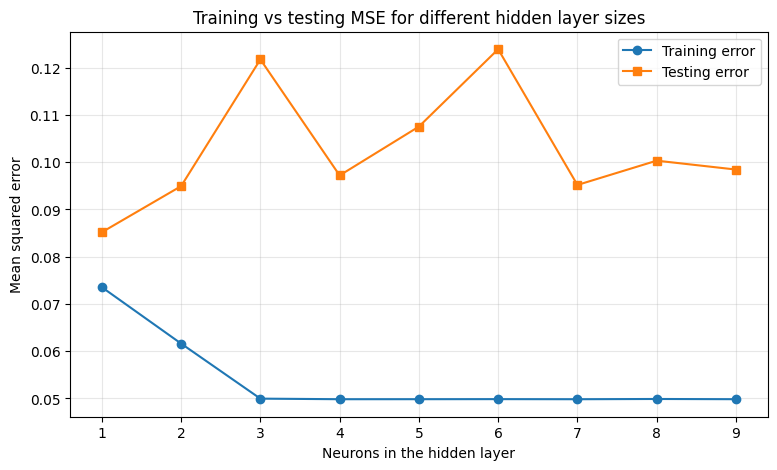

In [3]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, 10), training_errors, "o-", label="Training error")
plt.plot(range(1, 10), testing_errors, "s-", label="Testing error")
plt.xlabel("Neurons in the hidden layer"); plt.ylabel("Mean squared error")
plt.title("Training vs testing MSE for different hidden layer sizes")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("images/lab12_hidden_neurons.png")
plt.show()

More hidden neurons lower the training error, but the testing error does not fall with it. With only 80 training patients, larger networks start to fit noise.

## Report

1. **Zero initialisation:** every neuron in a layer computes the same output and receives the same gradient, so they stay identical (the symmetry problem). The network then behaves like a single neuron per layer.
2. **Epoch, batch, iteration:** an epoch is one pass over the whole training set. A batch is the subset of samples used for one weight update. An iteration is one such update, so the iterations per epoch equal the number of batches.
3. **SGD vs batch gradient descent:** SGD updates after every sample (fast, noisy, can escape shallow minima). Batch gradient descent uses the whole dataset per update (stable but slow, and can settle in poor minima).
4. **Fully random initialisation:** weights that are too large or too small cause exploding or vanishing gradients and unstable or failed training. Scaled schemes such as Xavier or He initialisation avoid this.
5. **Ten hyperparameters:** learning rate, number of hidden layers, neurons per layer, activation function, weight initialisation, batch size, number of epochs, regularisation (L1, L2, dropout), optimiser (SGD, Adam, RMSProp), and the error tolerance or early-stopping rule.